In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [10]:
from sklearn.linear_model import LinearRegression



In [11]:
from sklearn.linear_model import LogisticRegression

In [12]:
import statsmodels.api as sm

In [13]:
from google.colab import files

In [14]:
from sklearn.preprocessing import StandardScaler

In [15]:
from sklearn.cluster import KMeans

# Clustering

Is the process of dividing the dataset in different group consisting in similar data points.

It is useful to classify the customer to create market segmentation and make data informed decision for marketing

There are 3 different type of clustering

Exclusive -  which is when the points are exclusive of 1 of the 2 or more groups
This use as method the K-means

Overlapping - when groups share some points.
this use C-meaning method

Hierarchical - when all the cluster are combined such as matrioska

#K-mean -is the clustering whose goals is to group the similar datas into a cluster where the number of cluster is represented by K.

The simple example of how this works is when we wash clothes we try to group and wash them by color or type of fabric.

# How does the method works

- it regroups the points based on the the distance of each point from the nearest centroid

What a centroid is :* ' il centroide di un cluster è il punto che minimizza la somma delle distanze quadrate da tutti i punti del cluster stesso. Questo punto può essere calcolato come la media aritmetica delle coordinate dei punti appartenenti al cluster.'*

In [16]:
df=pd.DataFrame({'x':[12,20,28,18,29,33,24,45,45,52,51,52,55,53,55,61,64,69,72],
                 'y':[39,36,30,52,54,46,55,59,63,70,66,63,58,23,14,8,19,7,24]})

df

,x,y
0,12,39
1,20,36
2,28,30
3,18,52
4,29,54
5,33,46
6,24,55
7,45,59
8,45,63
9,52,70


In [17]:
np.random.seed(200)

Determining the optimal number of clusters, referred to as k, is crucial for the effectiveness of the K-means algorithm. One method commonly used for this choice is the elbow method (elbow method).

The elbow method involves running the K-means algorithm for different values of k and calculating, for each, the sum of the squared distances within clusters (Within-Cluster Sum of Squares or WCSS). Typically, as k increases, the WCSS decreases, since the data points are closer to the centroids of their clusters. However, there is a point where the reduction of WCSS slows down significantly: this point is called "elbow" and represents a good indication for the optimal number of clusters.

In [18]:
X = df[['x', 'y']].values

In [19]:
wcss = []

In [20]:
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

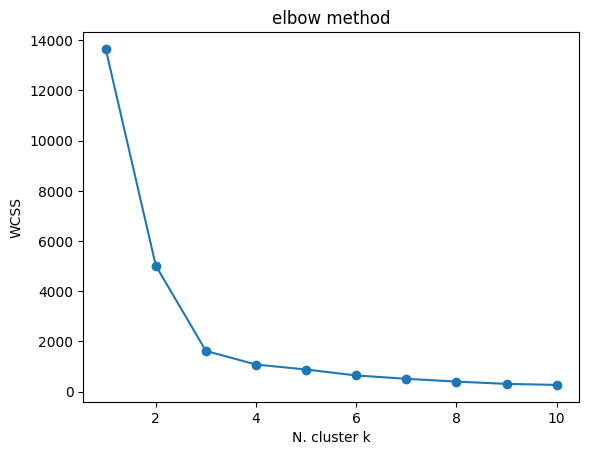

From the chart we can see that the elbow is at k=3


In [21]:

plt.plot(range(1,11), wcss, marker='o')
plt.title('elbow method')
plt.xlabel('N. cluster k')
plt.ylabel('WCSS')
plt.show()

print('From the chart we can see that the elbow is at k=3')

In [22]:
k=3

In [23]:

kmeans = KMeans(n_clusters=k, random_state=0)

In [24]:

kmeans.fit(X)

KMeans(n_clusters=3, random_state=0)

In [25]:
centroidi = kmeans.cluster_centers_
df_centroidi = pd.DataFrame(centroidi, columns=['x', 'y'])

In [26]:


y_kmeans = kmeans.predict(X)

In [27]:

df['Cluster'] = y_kmeans

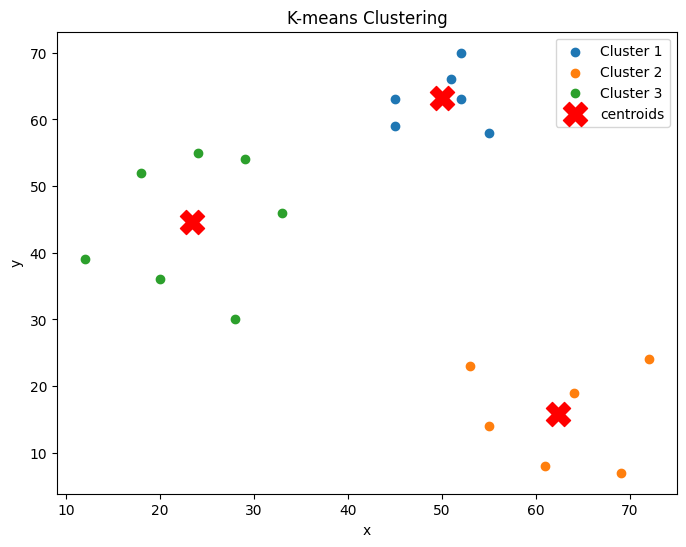

In [28]:

plt.figure(figsize=(8, 6))


for i in range(k):
    plt.scatter(df[df['Cluster'] == i]['x'], df[df['Cluster'] == i]['y'], label=f'Cluster {i+1}')

plt.scatter(df_centroidi['x'], df_centroidi['y'], s=300, c='red', marker='X', label='centroids')

plt.title('K-means Clustering')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [29]:
df

,x,y,Cluster
0,12,39,2
1,20,36,2
2,28,30,2
3,18,52,2
4,29,54,2
5,33,46,2
6,24,55,2
7,45,59,0
8,45,63,0
9,52,70,0
